# Heterogeneous ligand (two independent ligand populations): single-cycle kinetics (SCK)

Parameter-recovery benchmark. This notebook is AI generated, and has been reviewed by Osvaldo Burastero.

The data are simulated from the rate equations written below, integrated with SciPy (`solve_ivp`, Radau). No pykingenie function is used to make the data. The data are then fitted with pykingenie, using one Smax (Rmax) shared by all curves, and the fitted parameters are compared with the true ones. A parameter counts as recovered when its relative error is at most 5%.

Gaussian noise with a standard deviation of 0.5 RU is added, 1% of Rmax (50 RU). This is at the high end of real instruments: reference-subtracted SPR data typically show 0.1-0.5 RU of noise, and BLI 0.3-1% of a typical binding signal.


## Model

The surface holds two ligand populations that bind the analyte independently, each with 1:1 kinetics. Population 1 gives the fraction $f$ of the total response $R_{max}$:

$$\frac{dR_1}{dt} = k_{on,1}\,C\,(f R_{max} - R_1) - k_{off,1}\,R_1$$

$$\frac{dR_2}{dt} = k_{on,2}\,C\,((1-f) R_{max} - R_2) - k_{off,2}\,R_2, \qquad \text{signal} = R_1 + R_2$$

pykingenie reports `Kd1 [µM]`, `k_off1 [1/s]`, `Kd2 [µM]`, `k_off2 [1/s]`, `fraction_site1` and `Rmax`.

In [1]:
import sys

import numpy as np

sys.path.insert(0, '..')
from benchmark_helpers import simulate_sck, compare_parameters, plot_fit
from pykingenie.fitter_surface import KineticsFitter

## True parameters and experiment design

The concentrations are injected one after the other without regeneration: 120 s of injection and 60 s of buffer each, and 900 s of buffer after the last injection. Sampling every 1 s.

In [2]:
params = dict(kon1=1.0, koff1=0.01, kon2=0.5, koff2=0.1, fraction=0.4, Rmax=50.0)  # Kd1 = 0.01 µM, Kd2 = 0.2 µM
concs = [0.004, 0.016, 0.0625, 0.25, 1.0]  # µM, Kd1 = 0.01 and Kd2 = 0.2 µM

true_values = {'Kd1': params['koff1'] / params['kon1'], 'k_off1': params['koff1'],
               'Kd2': params['koff2'] / params['kon2'], 'k_off2': params['koff2'],
               'fraction_site1': params['fraction'], 'Smax': params['Rmax']}

## Rate equations (first principles)

In [3]:
def rhs(t, y, conc, p):
    R1, R2 = y
    dR1 = p['kon1'] * conc * (p['fraction'] * p['Rmax'] - R1) - p['koff1'] * R1
    dR2 = p['kon2'] * conc * ((1 - p['fraction']) * p['Rmax'] - R2) - p['koff2'] * R2
    return [dR1, dR2]


def signal(y, p):
    return y[:, 0] + y[:, 1]


y0 = [0.0, 0.0]

## Simulate the data

In [4]:
data = simulate_sck(rhs, signal, y0, params, concs, assoc_time=120.0, disso_time=60.0, final_disso_time=900.0, dt=1.0,
                    noise_sd=0.5, seed=0)

## Fit with pykingenie

One Smax shared by all curves (`smax_id` is 0 for every curve).

In [5]:
fitter = KineticsFitter(
    time_assoc_lst=data['time_assoc'], association_signal_lst=data['assoc'],
    lig_conc_lst=concs,
    time_diss_lst=data['time_disso'], dissociation_signal_lst=data['disso'],
    smax_id=[0] * len(concs), name_lst=['benchmark'], is_single_cycle=True,
)
fitter.get_steady_state()
fitter.fit_two_site_heterogeneous_ligand_assoc_and_disso(shared_smax=True)
fitter.fit_params_kinetics

,Kd1 [µM],k_off1 [1/s],Kd2 [µM],k_off2 [1/s],fraction_site1,Rmax,Name,(Derived) k_on1 [1/µM/s],(Derived) k_on2 [1/µM/s]
0,0.010026,0.01004,0.199522,0.099036,0.399573,49.963415,benchmark,1.001475,0.496365


## Compare with the true parameters

In [6]:
# The two populations can come out in either order: match them to the true
# populations by their k_off (population 1 dissociates more slowly)
site_a = (fitter.Kd1, fitter.k_off1, fitter.fraction_site1)
site_b = (fitter.Kd2, fitter.k_off2, 1 - fitter.fraction_site1)
site1, site2 = sorted([site_a, site_b], key=lambda site: site[1])
fitted_values = {'Kd1': site1[0], 'k_off1': site1[1], 'Kd2': site2[0], 'k_off2': site2[1],
                 'fraction_site1': site1[2], 'Smax': fitter.Smax[0]}

comparison = compare_parameters(true_values, fitted_values, rtol=0.05)
worst = comparison['rel. error (%)'].abs().idxmax()
print(f"All parameters recovered within 5%: {comparison['recovered'].all()}. "
      f"Largest error: {comparison.loc[worst, 'rel. error (%)']:+.2f}% ({worst})")
comparison

All parameters recovered within 5%: True. Largest error: -0.96% (k_off2)


,true,fitted,rel. error (%),recovered
parameter,,,,
Kd1,0.01,0.010026,0.256544,True
k_off1,0.01,0.010040,0.404403,True
Kd2,0.20,0.199522,-0.239105,True
k_off2,0.10,0.099036,-0.964300,True
fraction_site1,0.40,0.399573,-0.106696,True
Smax,50.00,49.963415,-0.073170,True


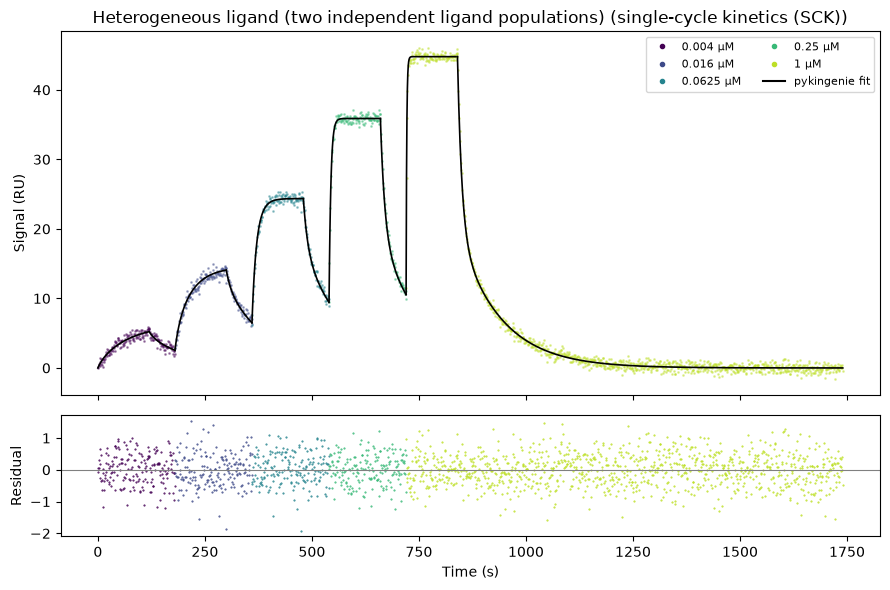

In [7]:
fig = plot_fit(data, fitter, concs, 'Heterogeneous ligand (two independent ligand populations) (single-cycle kinetics (SCK))')